In [52]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.13.0+cpu
CUDA available: False


In [53]:
# ============================================================
# STEP 2: SET DATASET PATHS
# ============================================================

import os

# CHANGE THESE TWO PATHS
BENIGN_DIR = r"C:\Users\student\venv\Scripts\Cancer\Breast cancer dataset\Benign"
ADENOCARCINOMA_DIR = r"C:\Users\student\venv\Scripts\Cancer\Breast cancer dataset\Malignant"


# Check whether the folders exist
print("Benign folder exists:",
      os.path.exists(BENIGN_DIR))

print("Adenocarcinoma folder exists:",
      os.path.exists(ADENOCARCINOMA_DIR))

Benign folder exists: True
Adenocarcinoma folder exists: True


In [54]:
# ============================================================
# STEP 3: COUNT AND VERIFY IMAGES
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
)

# Get Benign images
benign_files = [
    f for f in os.listdir(BENIGN_DIR)
    if f.lower().endswith(VALID_EXTENSIONS)
]

# Get Adenocarcinoma images
adenocarcinoma_files = [
    f for f in os.listdir(ADENOCARCINOMA_DIR)
    if f.lower().endswith(VALID_EXTENSIONS)
]

# Display counts
print("Number of Benign images       :", len(benign_files))
print("Number of Adenocarcinoma images:", len(adenocarcinoma_files))
print("Total images                  :", 
      len(benign_files) + len(adenocarcinoma_files))

Number of Benign images       : 1600
Number of Adenocarcinoma images: 1600
Total images                  : 3200


In [55]:
# ============================================================
# STEP 5: CREATE IMAGE PATHS AND LABELS
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# Benign = 0
# Adenocarcinoma/Malignant = 1
# ------------------------------------------------------------

image_paths = []
labels = []

# ------------------------------------------------------------
# Add Benign images
# ------------------------------------------------------------

for filename in benign_files:

    filepath = os.path.join(
        BENIGN_DIR,
        filename
    )

    image_paths.append(filepath)
    labels.append(0)


# ------------------------------------------------------------
# Add Adenocarcinoma/Malignant images
# ------------------------------------------------------------

for filename in adenocarcinoma_files:

    filepath = os.path.join(
        ADENOCARCINOMA_DIR,
        filename
    )

    image_paths.append(filepath)
    labels.append(1)


# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

data = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})


# ------------------------------------------------------------
# Shuffle
# ------------------------------------------------------------

data = data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ------------------------------------------------------------
# Display information
# ------------------------------------------------------------

print("=" * 60)
print("IMAGE PATH AND LABEL INFORMATION")
print("=" * 60)

print(
    "Total images:",
    len(data)
)

print(
    "\nClass distribution:"
)

print(
    data["label"].value_counts().sort_index()
)

print(
    "\nLabel mapping:"
)

print("0 → Benign")
print("1 → Adenocarcinoma/Malignant")

print("\nFirst 5 entries:")
print(
    data.head()
)

print("=" * 60)

IMAGE PATH AND LABEL INFORMATION
Total images: 3200

Class distribution:
label
0    1600
1    1600
Name: count, dtype: int64

Label mapping:
0 → Benign
1 → Adenocarcinoma/Malignant

First 5 entries:
                                          image_path  label
0  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
1  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
2  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
3  C:\Users\student\venv\Scripts\Cancer\Breast ca...      0
4  C:\Users\student\venv\Scripts\Cancer\Breast ca...      0


In [56]:
# ============================================================
# STEP 7: MCLAHE + COLOR NORMALIZATION
# NO DATA AUGMENTATION
# ============================================================

import cv2
import numpy as np

from PIL import Image
from torchvision import transforms


# ------------------------------------------------------------
# IMAGE SIZE
# ------------------------------------------------------------

IMAGE_SIZE = 224


# ------------------------------------------------------------
# MCLAHE
# ------------------------------------------------------------

def apply_mclahe(image):
    """
    Apply MCLAHE to an RGB image.
    """

    # RGB → LAB
    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    # Split LAB channels
    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    # Create CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    # Apply CLAHE to luminance channel
    l_channel = clahe.apply(
        l_channel
    )

    # Merge LAB channels
    lab = cv2.merge([
        l_channel,
        a_channel,
        b_channel
    ])

    # LAB → RGB
    enhanced_image = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    return enhanced_image


# ------------------------------------------------------------
# COLOR NORMALIZATION
# ------------------------------------------------------------

def apply_color_normalization(image):
    """
    Normalize RGB image intensity values.
    """

    image = image.astype(
        np.float32
    )

    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:

        image = (
            (image - min_value)
            /
            (max_value - min_value)
            * 255.0
        )

    image = np.clip(
        image,
        0,
        255
    )

    return image.astype(
        np.uint8
    )


# ------------------------------------------------------------
# COMBINED PREPROCESSING
# ------------------------------------------------------------

class MCLAHEColorNormalization:

    def __init__(
        self,
        image_size=224
    ):

        self.image_size = image_size

    def __call__(
        self,
        image
    ):

        # PIL → RGB NumPy
        image = np.array(
            image.convert("RGB")
        )

        # ----------------------------------------------------
        # MCLAHE
        # ----------------------------------------------------

        image = apply_mclahe(
            image
        )

        # ----------------------------------------------------
        # Color normalization
        # ----------------------------------------------------

        image = apply_color_normalization(
            image
        )

        # ----------------------------------------------------
        # Resize
        # ----------------------------------------------------

        image = cv2.resize(
            image,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_AREA
        )

        # NumPy → PIL
        image = Image.fromarray(
            image
        )

        return image


# ------------------------------------------------------------
# FINAL TRANSFORM
# ------------------------------------------------------------

image_transform = transforms.Compose([

    MCLAHEColorNormalization(
        image_size=IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ------------------------------------------------------------
# DISPLAY SETTINGS
# ------------------------------------------------------------

print("=" * 60)
print("PREPROCESSING CONFIGURATION")
print("=" * 60)

print("Image size              : 224 × 224")
print("MCLAHE                  : Applied")
print("Color normalization     : Applied")
print("Data augmentation       : NOT applied")
print("ImageNet normalization  : Applied")

print("=" * 60)

PREPROCESSING CONFIGURATION
Image size              : 224 × 224
MCLAHE                  : Applied
Color normalization     : Applied
Data augmentation       : NOT applied
ImageNet normalization  : Applied


In [57]:
# ============================================================
# STEP 5: CREATE DATAFRAME
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# Create image paths and labels
# ------------------------------------------------------------

filepaths = []
labels = []

# Benign = 0
for filename in benign_files:

    filepath = os.path.join(
        BENIGN_DIR,
        filename
    )

    filepaths.append(filepath)
    labels.append(0)


# Malignant/Adenocarcinoma = 1
for filename in adenocarcinoma_files:

    filepath = os.path.join(
        ADENOCARCINOMA_DIR,
        filename
    )

    filepaths.append(filepath)
    labels.append(1)


# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels
})


# ------------------------------------------------------------
# Shuffle
# ------------------------------------------------------------

df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ------------------------------------------------------------
# Display information
# ------------------------------------------------------------

print("=" * 60)
print("DATAFRAME CREATED")
print("=" * 60)

print("Total images:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

print("\nLabel mapping:")
print("0 → Benign")
print("1 → Malignant")

print("\nFirst 5 records:")
print(df.head())

print("=" * 60)

DATAFRAME CREATED
Total images: 3200

Class distribution:
label
0    1600
1    1600
Name: count, dtype: int64

Label mapping:
0 → Benign
1 → Malignant

First 5 records:
                                            filepath  label
0  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
1  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
2  C:\Users\student\venv\Scripts\Cancer\Breast ca...      1
3  C:\Users\student\venv\Scripts\Cancer\Breast ca...      0
4  C:\Users\student\venv\Scripts\Cancer\Breast ca...      0


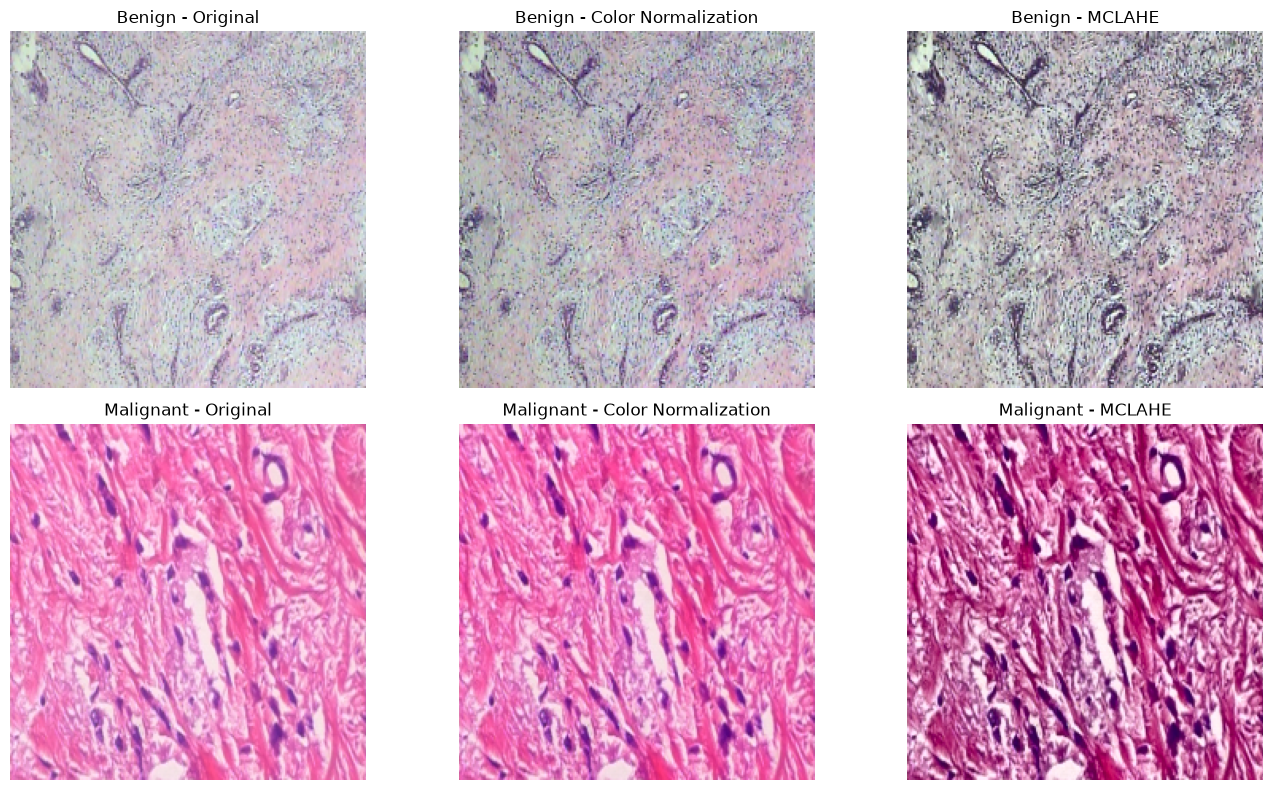

In [58]:
# ============================================================
# STEP 6: VISUALIZE PREPROCESSING
# ORIGINAL vs COLOR NORMALIZATION vs MCLAHE
# ============================================================

import matplotlib.pyplot as plt
import cv2
import numpy as np


# ------------------------------------------------------------
# SELECT ONE SAMPLE FROM EACH CLASS
# ------------------------------------------------------------

benign_sample = df[
    df["label"] == 0
].sample(
    n=1,
    random_state=42
).iloc[0]


malignant_sample = df[
    df["label"] == 1
].sample(
    n=1,
    random_state=42
).iloc[0]


samples = [
    ("Benign", benign_sample),
    ("Malignant", malignant_sample)
]


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 8)
)


# ------------------------------------------------------------
# PROCESS EACH SAMPLE
# ------------------------------------------------------------

for row_idx, (class_name, row) in enumerate(samples):

    filepath = row["filepath"]

    # Read image
    image = cv2.imread(filepath)

    if image is None:

        raise ValueError(
            f"Unable to read:\n{filepath}"
        )

    # BGR → RGB
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # ORIGINAL
    # --------------------------------------------------------

    original = cv2.resize(
        image,
        (224, 224)
    )


    # --------------------------------------------------------
    # COLOR NORMALIZATION
    # --------------------------------------------------------

    normalized = image.astype(
        np.float32
    )

    min_value = normalized.min()
    max_value = normalized.max()

    if max_value > min_value:

        normalized = (
            (normalized - min_value)
            /
            (max_value - min_value)
            * 255.0
        )

    normalized = np.clip(
        normalized,
        0,
        255
    ).astype(np.uint8)

    normalized = cv2.resize(
        normalized,
        (224, 224)
    )


    # --------------------------------------------------------
    # MCLAHE
    # --------------------------------------------------------

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(
        lab
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_channel = clahe.apply(
        l_channel
    )

    lab = cv2.merge([
        l_channel,
        a_channel,
        b_channel
    ])

    mclahe = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    mclahe = cv2.resize(
        mclahe,
        (224, 224)
    )


    # --------------------------------------------------------
    # DISPLAY ORIGINAL
    # --------------------------------------------------------

    plt.subplot(
        2,
        3,
        row_idx * 3 + 1
    )

    plt.imshow(original)

    plt.title(
        f"{class_name} - Original"
    )

    plt.axis("off")


    # --------------------------------------------------------
    # DISPLAY COLOR NORMALIZATION
    # --------------------------------------------------------

    plt.subplot(
        2,
        3,
        row_idx * 3 + 2
    )

    plt.imshow(normalized)

    plt.title(
        f"{class_name} - Color Normalization"
    )

    plt.axis("off")


    # --------------------------------------------------------
    # DISPLAY MCLAHE
    # --------------------------------------------------------

    plt.subplot(
        2,
        3,
        row_idx * 3 + 3
    )

    plt.imshow(mclahe)

    plt.title(
        f"{class_name} - MCLAHE"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# STEP 7: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 80% Training + 20% Temporary
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)


# ------------------------------------------------------------
# 10% Validation + 10% Test
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)


# ------------------------------------------------------------
# Reset indices
# ------------------------------------------------------------

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ------------------------------------------------------------
# Display split information
# ------------------------------------------------------------

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Total images      :", len(df))
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))


# ------------------------------------------------------------
# Display percentages
# ------------------------------------------------------------

print("\nSplit percentages:")

print(
    f"Training   : {len(train_df)/len(df)*100:.2f}%"
)

print(
    f"Validation : {len(val_df)/len(df)*100:.2f}%"
)

print(
    f"Testing    : {len(test_df)/len(df)*100:.2f}%"
)


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("CLASS DISTRIBUTION")
print("-" * 60)

print("\nTraining:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

print("\nTesting:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Label mapping
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("LABEL MAPPING")
print("-" * 60)

print("0 → Benign")
print("1 → Malignant")


print("\n" + "=" * 60)
print("DATASET SPLIT COMPLETED")
print("=" * 60)

DATASET SPLIT
Total images      : 3200
Training images   : 2560
Validation images : 320
Testing images    : 320

Split percentages:
Training   : 80.00%
Validation : 10.00%
Testing    : 10.00%

------------------------------------------------------------
CLASS DISTRIBUTION
------------------------------------------------------------

Training:
label
0    1280
1    1280
Name: count, dtype: int64

Validation:
label
0    160
1    160
Name: count, dtype: int64

Testing:
label
0    160
1    160
Name: count, dtype: int64

------------------------------------------------------------
LABEL MAPPING
------------------------------------------------------------
0 → Benign
1 → Malignant

DATASET SPLIT COMPLETED


In [60]:
# ============================================================
# STEP 8: CUSTOM PYTORCH DATASET
# ============================================================

import torch

from torch.utils.data import Dataset
from PIL import Image


class BreastCancerDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    # --------------------------------------------------------
    # Number of samples
    # --------------------------------------------------------

    def __len__(self):

        return len(
            self.dataframe
        )


    # --------------------------------------------------------
    # Load one sample
    # --------------------------------------------------------

    def __getitem__(
        self,
        index
    ):

        # Get row
        row = self.dataframe.iloc[index]

        # Image path
        image_path = row["filepath"]

        # Label
        label = int(
            row["label"]
        )

        # ----------------------------------------------------
        # Read image
        # ----------------------------------------------------

        try:

            image = Image.open(
                image_path
            ).convert("RGB")

        except Exception as e:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}\n"
                f"Error: {e}"
            )


        # ----------------------------------------------------
        # Apply MCLAHE + Color Normalization
        # ----------------------------------------------------

        if self.transform is not None:

            image = self.transform(
                image
            )


        # ----------------------------------------------------
        # Convert label to tensor
        # ----------------------------------------------------

        label = torch.tensor(
            label,
            dtype=torch.long
        )


        return image, label

In [61]:
# ============================================================
# CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================

train_dataset = BreastCancerDataset(
    dataframe=train_df,
    transform=image_transform
)

val_dataset = BreastCancerDataset(
    dataframe=val_df,
    transform=image_transform
)

test_dataset = BreastCancerDataset(
    dataframe=test_df,
    transform=image_transform
)


print("=" * 60)
print("PYTORCH DATASETS CREATED")
print("=" * 60)

print(
    "Training samples   :",
    len(train_dataset)
)

print(
    "Validation samples :",
    len(val_dataset)
)

print(
    "Testing samples    :",
    len(test_dataset)
)

print("=" * 60)

PYTORCH DATASETS CREATED
Training samples   : 2560
Validation samples : 320
Testing samples    : 320


In [62]:
# ============================================================
# VERIFY ONE DATASET SAMPLE
# ============================================================

sample_image, sample_label = train_dataset[0]

print("=" * 60)
print("DATASET SAMPLE VERIFICATION")
print("=" * 60)

print(
    "Image tensor shape :",
    sample_image.shape
)

print(
    "Image data type    :",
    sample_image.dtype
)

print(
    "Label              :",
    sample_label.item()
)

print(
    "Label name         :",
    "Benign"
    if sample_label.item() == 0
    else "Malignant"
)

print(
    "Image minimum      :",
    sample_image.min().item()
)

print(
    "Image maximum      :",
    sample_image.max().item()
)

print("=" * 60)

DATASET SAMPLE VERIFICATION
Image tensor shape : torch.Size([3, 224, 224])
Image data type    : torch.float32
Label              : 1
Label name         : Malignant
Image minimum      : -1.9131652116775513
Image maximum      : 2.640000104904175


In [63]:
# ============================================================
# STEP 9: CREATE TRAIN / VALIDATION / TEST DATALOADERS
# ============================================================

from torch.utils.data import DataLoader


# ------------------------------------------------------------
# BATCH SIZE
# ------------------------------------------------------------

BATCH_SIZE = 32


# ------------------------------------------------------------
# NUMBER OF WORKERS
# ------------------------------------------------------------

# For Windows/Jupyter, 0 is safer.
NUM_WORKERS = 0


# ------------------------------------------------------------
# TRAIN DATALOADER
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# VALIDATION DATALOADER
# ------------------------------------------------------------

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# TEST DATALOADER
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# DISPLAY INFORMATION
# ------------------------------------------------------------

print("=" * 60)
print("DATALOADERS CREATED")
print("=" * 60)

print(
    "Batch size       :",
    BATCH_SIZE
)

print(
    "Training batches :",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Testing batches  :",
    len(test_loader)
)

print(
    "Workers          :",
    NUM_WORKERS
)

print("=" * 60)

DATALOADERS CREATED
Batch size       : 32
Training batches : 80
Validation batches: 10
Testing batches  : 10
Workers          : 0


In [64]:
# ============================================================
# STEP 9A: VERIFY DATALOADER BATCH
# ============================================================

images, labels = next(
    iter(train_loader)
)

print("=" * 60)
print("DATALOADER BATCH VERIFICATION")
print("=" * 60)

print(
    "Image batch shape :",
    images.shape
)

print(
    "Label batch shape :",
    labels.shape
)

print(
    "Image dtype       :",
    images.dtype
)

print(
    "Label dtype       :",
    labels.dtype
)

print(
    "Labels in batch   :",
    labels.unique().tolist()
)

print("=" * 60)

DATALOADER BATCH VERIFICATION
Image batch shape : torch.Size([32, 3, 224, 224])
Label batch shape : torch.Size([32])
Image dtype       : torch.float32
Label dtype       : torch.int64
Labels in batch   : [0, 1]


In [65]:
# ============================================================
# STEP 10.1: CNN BRANCH
# ============================================================

import torch
import torch.nn as nn


class CNNBranch(nn.Module):

    def __init__(self, branch_type="fine_texture"):

        super().__init__()

        self.branch_type = branch_type


        # ====================================================
        # BRANCH 1: FINE TEXTURE
        # ====================================================

        if branch_type == "fine_texture":

            self.features = nn.Sequential(

                nn.Conv2d(
                    3, 32,
                    kernel_size=3,
                    padding=1
                ),

                nn.BatchNorm2d(32),

                nn.ReLU(inplace=True),


                nn.Conv2d(
                    32, 64,
                    kernel_size=3,
                    padding=1
                ),

                nn.BatchNorm2d(64),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2),


                nn.Conv2d(
                    64, 128,
                    kernel_size=3,
                    padding=1
                ),

                nn.BatchNorm2d(128),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2)
            )


        # ====================================================
        # BRANCH 2: STRUCTURAL
        # ====================================================

        elif branch_type == "structural":

            self.features = nn.Sequential(

                nn.Conv2d(
                    3, 32,
                    kernel_size=5,
                    padding=2
                ),

                nn.BatchNorm2d(32),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2),


                nn.Conv2d(
                    32, 64,
                    kernel_size=5,
                    padding=2
                ),

                nn.BatchNorm2d(64),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2),


                nn.Conv2d(
                    64, 128,
                    kernel_size=3,
                    padding=1
                ),

                nn.BatchNorm2d(128),

                nn.ReLU(inplace=True)
            )


        # ====================================================
        # BRANCH 3: GLOBAL CONTEXT
        # ====================================================

        elif branch_type == "global_context":

            self.features = nn.Sequential(

                nn.Conv2d(
                    3, 32,
                    kernel_size=3,
                    padding=2,
                    dilation=2
                ),

                nn.BatchNorm2d(32),

                nn.ReLU(inplace=True),


                nn.Conv2d(
                    32, 64,
                    kernel_size=3,
                    padding=2,
                    dilation=2
                ),

                nn.BatchNorm2d(64),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2),


                nn.Conv2d(
                    64, 128,
                    kernel_size=3,
                    padding=4,
                    dilation=4
                ),

                nn.BatchNorm2d(128),

                nn.ReLU(inplace=True),


                nn.MaxPool2d(2)
            )


        else:

            raise ValueError(
                "Unknown branch type: "
                f"{branch_type}"
            )


        # ====================================================
        # GLOBAL AVERAGE POOLING
        # ====================================================

        self.global_pool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(self, x):

        x = self.features(x)

        x = self.global_pool(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        return x

In [66]:
# ============================================================
# STEP 10.2: TRI-BRANCH CNN
# ============================================================

class TriBranchCNN(nn.Module):

    def __init__(self):

        super().__init__()


        # ----------------------------------------------------
        # THREE CNN BRANCHES
        # ----------------------------------------------------

        self.fine_texture_branch = CNNBranch(
            branch_type="fine_texture"
        )


        self.structural_branch = CNNBranch(
            branch_type="structural"
        )


        self.global_context_branch = CNNBranch(
            branch_type="global_context"
        )


        # ----------------------------------------------------
        # FEATURE DIMENSION
        # ----------------------------------------------------

        self.feature_dim = 128


    # --------------------------------------------------------
    # FORWARD
    # --------------------------------------------------------

    def forward(self, x):

        # Fine texture features
        fine_features = (
            self.fine_texture_branch(x)
        )


        # Structural features
        structural_features = (
            self.structural_branch(x)
        )


        # Global context features
        global_features = (
            self.global_context_branch(x)
        )


        return (
            fine_features,
            structural_features,
            global_features
        )

In [67]:
# ============================================================
# STEP 10.2: SET COMPUTATION DEVICE
# ============================================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("COMPUTATION DEVICE")
print("=" * 60)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

print("=" * 60)

COMPUTATION DEVICE
Device: cpu
GPU not available. Using CPU.


In [68]:
# ============================================================
# STEP 10.3: CREATE TRI-BRANCH CNN MODEL
# ============================================================

cnn_model = TriBranchCNN()

cnn_model = cnn_model.to(device)


print("=" * 60)
print("TRI-BRANCH CNN CREATED")
print("=" * 60)

print(
    "Branch 1 : Fine Texture"
)

print(
    "Branch 2 : Structural"
)

print(
    "Branch 3 : Global Context"
)

print(
    "Feature dimension per branch:",
    cnn_model.feature_dim
)

print("=" * 60)

TRI-BRANCH CNN CREATED
Branch 1 : Fine Texture
Branch 2 : Structural
Branch 3 : Global Context
Feature dimension per branch: 128


In [69]:
# ============================================================
# STEP 10.4: VERIFY TRI-BRANCH CNN
# ============================================================

cnn_model.eval()


# ------------------------------------------------------------
# GET ONE BATCH
# ------------------------------------------------------------

images, labels = next(
    iter(train_loader)
)


# ------------------------------------------------------------
# MOVE TO DEVICE
# ------------------------------------------------------------

images = images.to(device)


# ------------------------------------------------------------
# EXTRACT FEATURES
# ------------------------------------------------------------

with torch.no_grad():

    fine_features, \
    structural_features, \
    global_features = cnn_model(
        images
    )


# ------------------------------------------------------------
# DISPLAY SHAPES
# ------------------------------------------------------------

print("=" * 60)
print("TRI-BRANCH FEATURE VERIFICATION")
print("=" * 60)

print(
    "Input:",
    images.shape
)

print(
    "Fine Texture:",
    fine_features.shape
)

print(
    "Structural:",
    structural_features.shape
)

print(
    "Global Context:",
    global_features.shape
)

print("=" * 60)

TRI-BRANCH FEATURE VERIFICATION
Input: torch.Size([32, 3, 224, 224])
Fine Texture: torch.Size([32, 128])
Structural: torch.Size([32, 128])
Global Context: torch.Size([32, 128])


In [70]:
# ============================================================
# STEP 10.5: FEATURE CONCATENATION
# ============================================================

with torch.no_grad():

    concatenated_features = torch.cat(
        [
            fine_features,
            structural_features,
            global_features
        ],
        dim=1
    )


print("=" * 60)
print("FEATURE CONCATENATION")
print("=" * 60)

print(
    "Fine Texture features :",
    fine_features.shape
)

print(
    "Structural features   :",
    structural_features.shape
)

print(
    "Global Context features:",
    global_features.shape
)

print(
    "Concatenated features :",
    concatenated_features.shape
)

print("=" * 60)

FEATURE CONCATENATION
Fine Texture features : torch.Size([32, 128])
Structural features   : torch.Size([32, 128])
Global Context features: torch.Size([32, 128])
Concatenated features : torch.Size([32, 384])


In [71]:
# ============================================================
# STEP 10.6: EXTRACT TRI-BRANCH FEATURES
# AND SAVE TO EXCEL
# ============================================================

import torch
import pandas as pd
import numpy as np
from tqdm import tqdm


# ------------------------------------------------------------
# FUNCTION TO EXTRACT FEATURES
# ------------------------------------------------------------

def extract_features_to_excel(
    model,
    dataloader,
    dataframe,
    output_file
):

    model.eval()

    all_features = []
    all_labels = []
    all_paths = []


    # --------------------------------------------------------
    # Disable gradient calculation
    # --------------------------------------------------------

    with torch.no_grad():

        for images, labels in tqdm(
            dataloader,
            desc="Extracting features"
        ):

            # Move images to device
            images = images.to(device)


            # ------------------------------------------------
            # Extract three branch features
            # ------------------------------------------------

            fine_features, \
            structural_features, \
            global_features = model(images)


            # ------------------------------------------------
            # Concatenate features
            # ------------------------------------------------

            concatenated_features = torch.cat(
                [
                    fine_features,
                    structural_features,
                    global_features
                ],
                dim=1
            )


            # ------------------------------------------------
            # Move to CPU
            # ------------------------------------------------

            concatenated_features = (
                concatenated_features
                .cpu()
                .numpy()
            )


            # ------------------------------------------------
            # Store
            # ------------------------------------------------

            all_features.append(
                concatenated_features
            )

            all_labels.extend(
                labels.cpu().numpy()
            )


    # --------------------------------------------------------
    # Combine all batches
    # --------------------------------------------------------

    all_features = np.vstack(
        all_features
    )


    # --------------------------------------------------------
    # Get file paths
    #
    # Dataloader is not shuffled for validation/test.
    # Training loader is shuffled, so we use the dataframe
    # order only when extracting with a non-shuffled loader.
    # --------------------------------------------------------

    all_paths = dataframe[
        "filepath"
    ].tolist()


    # --------------------------------------------------------
    # Verify number of samples
    # --------------------------------------------------------

    if len(all_features) != len(dataframe):

        raise ValueError(
            "Feature count does not match "
            "DataFrame count. "
            f"Features: {len(all_features)}, "
            f"DataFrame: {len(dataframe)}"
        )


    # --------------------------------------------------------
    # Create feature column names
    # --------------------------------------------------------

    feature_columns = [

        f"Feature_{i+1}"

        for i in range(
            all_features.shape[1]
        )
    ]


    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    feature_df = pd.DataFrame(
        all_features,
        columns=feature_columns
    )


    # --------------------------------------------------------
    # Add filepath and label
    # --------------------------------------------------------

    feature_df.insert(
        0,
        "filepath",
        all_paths
    )

    feature_df.insert(
        1,
        "label",
        dataframe["label"].values
    )


    # --------------------------------------------------------
    # Save Excel file
    # --------------------------------------------------------

    feature_df.to_excel(
        output_file,
        index=False
    )


    # --------------------------------------------------------
    # Display information
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("FEATURE EXTRACTION COMPLETED")
    print("=" * 60)

    print(
        "Number of samples :",
        len(feature_df)
    )

    print(
        "Number of features:",
        all_features.shape[1]
    )

    print(
        "Excel file:",
        output_file
    )

    print("=" * 60)


    return feature_df

In [72]:
# ============================================================
# STEP 10.7: NON-SHUFFLED FEATURE EXTRACTION DATALOADERS
# ============================================================

train_extract_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


val_extract_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


test_extract_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Feature extraction DataLoaders created.")

Feature extraction DataLoaders created.


In [73]:
# ============================================================
# SAVE TRAINING FEATURES
# ============================================================

train_feature_df = extract_features_to_excel(
    model=cnn_model,
    dataloader=train_extract_loader,
    dataframe=train_df,
    output_file="TriBranch_Train_Features.xlsx"
)

Extracting features: 100%|██████████| 80/80 [03:41<00:00,  2.76s/it]



FEATURE EXTRACTION COMPLETED
Number of samples : 2560
Number of features: 384
Excel file: TriBranch_Train_Features.xlsx


In [74]:
# ============================================================
# SAVE VALIDATION FEATURES
# ============================================================

val_feature_df = extract_features_to_excel(
    model=cnn_model,
    dataloader=val_extract_loader,
    dataframe=val_df,
    output_file="TriBranch_Validation_Features.xlsx"
)

Extracting features: 100%|██████████| 10/10 [00:27<00:00,  2.74s/it]



FEATURE EXTRACTION COMPLETED
Number of samples : 320
Number of features: 384
Excel file: TriBranch_Validation_Features.xlsx


In [75]:
# ============================================================
# SAVE TEST FEATURES
# ============================================================

test_feature_df = extract_features_to_excel(
    model=cnn_model,
    dataloader=test_extract_loader,
    dataframe=test_df,
    output_file="TriBranch_Test_Features.xlsx"
)

Extracting features: 100%|██████████| 10/10 [00:27<00:00,  2.77s/it]



FEATURE EXTRACTION COMPLETED
Number of samples : 320
Number of features: 384
Excel file: TriBranch_Test_Features.xlsx


In [76]:
# ============================================================
# STEP 16.1: IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler

In [77]:
# ============================================================
# STEP 16: LOAD TRI-BRANCH FUSED FEATURES
# ============================================================

import pandas as pd
import numpy as np

TRAIN_FILE = "TriBranch_Train_Features.xlsx"
VAL_FILE   = "TriBranch_Validation_Features.xlsx"
TEST_FILE  = "TriBranch_Test_Features.xlsx"


train_feature_df = pd.read_excel(
    TRAIN_FILE
)

val_feature_df = pd.read_excel(
    VAL_FILE
)

test_feature_df = pd.read_excel(
    TEST_FILE
)


print("=" * 70)
print("FEATURE DATASET INFORMATION")
print("=" * 70)

print(
    "Training shape   :",
    train_feature_df.shape
)

print(
    "Validation shape :",
    val_feature_df.shape
)

print(
    "Testing shape    :",
    test_feature_df.shape
)

print("=" * 70)

FEATURE DATASET INFORMATION
Training shape   : (2560, 386)
Validation shape : (320, 386)
Testing shape    : (320, 386)


In [78]:
# ============================================================
# STEP 17: IDENTIFY FEATURE AND LABEL COLUMNS
# ============================================================

# ------------------------------------------------------------
# Label column
# ------------------------------------------------------------

LABEL_COLUMN = "label"


# ------------------------------------------------------------
# Columns that should NOT be used as features
# ------------------------------------------------------------

NON_FEATURE_COLUMNS = [
    "label",
    "filepath",
    "filename",
    "image",
    "class"
]


# ------------------------------------------------------------
# Automatically identify numerical feature columns
# ------------------------------------------------------------

feature_columns = [
    col
    for col in train_feature_df.columns
    if col not in NON_FEATURE_COLUMNS
    and pd.api.types.is_numeric_dtype(
        train_feature_df[col]
    )
]


print("=" * 70)
print("FEATURE INFORMATION")
print("=" * 70)

print(
    "Number of fused features:",
    len(feature_columns)
)

print(
    "Label column:",
    LABEL_COLUMN
)

print(
    "First 10 features:"
)

print(
    feature_columns[:10]
)

print("=" * 70)

FEATURE INFORMATION
Number of fused features: 384
Label column: label
First 10 features:
['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Feature_8', 'Feature_9', 'Feature_10']


In [79]:
# ============================================================
# STEP 18: CREATE FEATURE MATRICES
# ============================================================

X_train = train_feature_df[
    feature_columns
].values.astype(
    np.float32
)

y_train = train_feature_df[
    LABEL_COLUMN
].values.astype(
    np.int64
)


X_val = val_feature_df[
    feature_columns
].values.astype(
    np.float32
)

y_val = val_feature_df[
    LABEL_COLUMN
].values.astype(
    np.int64
)


X_test = test_feature_df[
    feature_columns
].values.astype(
    np.float32
)

y_test = test_feature_df[
    LABEL_COLUMN
].values.astype(
    np.int64
)


print("=" * 70)
print("FEATURE MATRICES")
print("=" * 70)

print(
    "X_train:",
    X_train.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "y_val:",
    y_val.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)

print("=" * 70)

FEATURE MATRICES
X_train: (2560, 384)
y_train: (2560,)
X_val: (320, 384)
y_val: (320,)
X_test: (320, 384)
y_test: (320,)


In [80]:
# ============================================================
# STEP 19: FEATURE STANDARDIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(
    X_train
)

X_val_scaled = scaler.transform(
    X_val
)

X_test_scaled = scaler.transform(
    X_test
)


print("=" * 70)
print("FEATURE STANDARDIZATION COMPLETED")
print("=" * 70)

print(
    "Training:",
    X_train_scaled.shape
)

print(
    "Validation:",
    X_val_scaled.shape
)

print(
    "Testing:",
    X_test_scaled.shape
)

print("=" * 70)

FEATURE STANDARDIZATION COMPLETED
Training: (2560, 384)
Validation: (320, 384)
Testing: (320, 384)


In [81]:
# ============================================================
# STEP 20.1: ATTENTION-BASED FEATURE REFINEMENT
# ============================================================

import torch
import torch.nn as nn


class FeatureAttention(nn.Module):

    def __init__(
        self,
        input_dim=384,
        reduction=4
    ):

        super().__init__()


        # ----------------------------------------------------
        # Attention bottleneck
        # ----------------------------------------------------

        hidden_dim = input_dim // reduction


        self.attention = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                input_dim
            ),

            nn.Sigmoid()
        )


    def forward(self, x):

        # ----------------------------------------------------
        # Generate attention weights
        # ----------------------------------------------------

        attention_weights = self.attention(
            x
        )


        # ----------------------------------------------------
        # Feature refinement
        # ----------------------------------------------------

        refined_features = (
            x * attention_weights
        )


        return (
            refined_features,
            attention_weights
        )

In [82]:
# ============================================================
# STEP 20.2: CREATE ATTENTION MODEL
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


attention_model = FeatureAttention(
    input_dim=X_train_scaled.shape[1],
    reduction=4
).to(device)


print("=" * 70)
print("ATTENTION MODEL")
print("=" * 70)

print(
    attention_model
)

print("=" * 70)

ATTENTION MODEL
FeatureAttention(
  (attention): Sequential(
    (0): Linear(in_features=384, out_features=96, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=96, out_features=384, bias=True)
    (3): Sigmoid()
  )
)


In [83]:
# ============================================================
# STEP 21: ATTENTION + CLASSIFICATION NETWORK
# ============================================================

class AttentionClassifier(nn.Module):

    def __init__(
        self,
        input_dim=384,
        reduction=4,
        num_classes=2
    ):

        super().__init__()


        hidden_dim = input_dim // reduction


        # ----------------------------------------------------
        # Attention module
        # ----------------------------------------------------

        self.attention = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                input_dim
            ),

            nn.Sigmoid()
        )


        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                input_dim,
                128
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        # Attention weights
        attention_weights = self.attention(
            x
        )


        # Refined features
        refined_features = (
            x * attention_weights
        )


        # Classification
        output = self.classifier(
            refined_features
        )


        return (
            output,
            refined_features,
            attention_weights
        )

In [84]:
# ============================================================
# STEP 22: CONVERT FEATURES TO PYTORCH TENSORS
# ============================================================

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
).to(device)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
).to(device)


X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
).to(device)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
).to(device)


X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
).to(device)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
).to(device)


print(
    "Training tensor:",
    X_train_tensor.shape
)

print(
    "Validation tensor:",
    X_val_tensor.shape
)

print(
    "Testing tensor:",
    X_test_tensor.shape
)

Training tensor: torch.Size([2560, 384])
Validation tensor: torch.Size([320, 384])
Testing tensor: torch.Size([320, 384])


In [85]:
# ============================================================
# STEP 23: TRAIN ATTENTION-BASED FEATURE REFINEMENT
# ============================================================

from torch.utils.data import TensorDataset, DataLoader


BATCH_SIZE = 32

NUM_EPOCHS = 30

LEARNING_RATE = 0.001


train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


attention_classifier = AttentionClassifier(
    input_dim=X_train_scaled.shape[1],
    reduction=4,
    num_classes=2
).to(device)


criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.Adam(
    attention_classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


print(
    "Attention training started..."
)

Attention training started...


In [86]:
# ============================================================
# STEP 24: TRAINING LOOP
# ============================================================

best_val_accuracy = 0.0

best_attention_state = None


for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAIN
    # ========================================================

    attention_classifier.train()

    correct = 0
    total = 0
    train_loss = 0.0


    for features, labels in train_loader:

        optimizer.zero_grad()


        outputs, refined, weights = (
            attention_classifier(features)
        )


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()

        optimizer.step()


        train_loss += (
            loss.item()
            * labels.size(0)
        )


        predictions = torch.argmax(
            outputs,
            dim=1
        )


        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss /= total

    train_accuracy = (
        100.0 * correct / total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    attention_classifier.eval()

    val_correct = 0
    val_total = 0
    val_loss = 0.0


    with torch.no_grad():

        for features, labels in val_loader:

            outputs, refined, weights = (
                attention_classifier(
                    features
                )
            )


            loss = criterion(
                outputs,
                labels
            )


            val_loss += (
                loss.item()
                * labels.size(0)
            )


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss /= val_total

    val_accuracy = (
        100.0
        * val_correct
        / val_total
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        best_attention_state = {
            key: value.detach().cpu().clone()
            for key, value
            in attention_classifier.state_dict().items()
        }


    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


# ------------------------------------------------------------
# Restore best model
# ------------------------------------------------------------

attention_classifier.load_state_dict(
    best_attention_state
)


print("\n" + "=" * 70)

print(
    "ATTENTION TRAINING COMPLETED"
)

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.2f}%"
)

print("=" * 70)

Epoch [01/30] | Train Loss: 0.4781 | Train Acc: 78.09% | Val Loss: 0.3840 | Val Acc: 80.00%
Epoch [02/30] | Train Loss: 0.3821 | Train Acc: 83.01% | Val Loss: 0.3661 | Val Acc: 81.56%
Epoch [03/30] | Train Loss: 0.3399 | Train Acc: 84.88% | Val Loss: 0.2900 | Val Acc: 87.81%
Epoch [04/30] | Train Loss: 0.2985 | Train Acc: 87.38% | Val Loss: 0.2694 | Val Acc: 87.81%
Epoch [05/30] | Train Loss: 0.2580 | Train Acc: 88.71% | Val Loss: 0.2215 | Val Acc: 89.69%
Epoch [06/30] | Train Loss: 0.2317 | Train Acc: 89.34% | Val Loss: 0.2257 | Val Acc: 90.00%
Epoch [07/30] | Train Loss: 0.2025 | Train Acc: 91.29% | Val Loss: 0.2173 | Val Acc: 89.06%
Epoch [08/30] | Train Loss: 0.1799 | Train Acc: 92.73% | Val Loss: 0.1832 | Val Acc: 92.19%
Epoch [09/30] | Train Loss: 0.1619 | Train Acc: 93.52% | Val Loss: 0.1941 | Val Acc: 90.62%
Epoch [10/30] | Train Loss: 0.1411 | Train Acc: 94.41% | Val Loss: 0.2492 | Val Acc: 90.94%
Epoch [11/30] | Train Loss: 0.1319 | Train Acc: 94.34% | Val Loss: 0.1967 | Val 

In [87]:
# ============================================================
# STEP 25: EXTRACT ATTENTION-REFINED FEATURES
# ============================================================

def extract_attention_features(
    model,
    X,
    device
):

    model.eval()


    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(device)


    with torch.no_grad():

        attention_weights = model.attention(
            X_tensor
        )

        refined_features = (
            X_tensor
            * attention_weights
        )


    return (
        refined_features.cpu().numpy(),
        attention_weights.cpu().numpy()
    )


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

X_train_attention, train_attention_weights = (
    extract_attention_features(
        attention_classifier,
        X_train_scaled,
        device
    )
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

X_val_attention, val_attention_weights = (
    extract_attention_features(
        attention_classifier,
        X_val_scaled,
        device
    )
)


# ------------------------------------------------------------
# Testing
# ------------------------------------------------------------

X_test_attention, test_attention_weights = (
    extract_attention_features(
        attention_classifier,
        X_test_scaled,
        device
    )
)


print("=" * 70)

print(
    "ATTENTION-REFINED FEATURES"
)

print(
    "Training:",
    X_train_attention.shape
)

print(
    "Validation:",
    X_val_attention.shape
)

print(
    "Testing:",
    X_test_attention.shape
)

print("=" * 70)

ATTENTION-REFINED FEATURES
Training: (2560, 384)
Validation: (320, 384)
Testing: (320, 384)


In [88]:
# ============================================================
# STEP 26: SAVE ATTENTION-REFINED FEATURES
# ============================================================

attention_feature_columns = [
    f"Attention_Feature_{i+1}"
    for i in range(
        X_train_attention.shape[1]
    )
]


train_attention_df = pd.DataFrame(
    X_train_attention,
    columns=attention_feature_columns
)

train_attention_df["label"] = y_train


val_attention_df = pd.DataFrame(
    X_val_attention,
    columns=attention_feature_columns
)

val_attention_df["label"] = y_val


test_attention_df = pd.DataFrame(
    X_test_attention,
    columns=attention_feature_columns
)

test_attention_df["label"] = y_test


train_attention_df.to_excel(
    "TriBranch_Attention_Train_Features.xlsx",
    index=False
)

val_attention_df.to_excel(
    "TriBranch_Attention_Validation_Features.xlsx",
    index=False
)

test_attention_df.to_excel(
    "TriBranch_Attention_Test_Features.xlsx",
    index=False
)


print(
    "Attention-refined features saved successfully."
)

Attention-refined features saved successfully.


In [89]:
# ============================================================
# STEP 27: BRANCH-WISE ATTENTION ANALYSIS
# ============================================================

fine_texture_attention = np.mean(
    test_attention_weights[:, 0:128]
)

structural_attention = np.mean(
    test_attention_weights[:, 128:256]
)

global_context_attention = np.mean(
    test_attention_weights[:, 256:384]
)


branch_attention_df = pd.DataFrame({

    "Branch": [
        "Fine Texture",
        "Structural",
        "Global Context"
    ],

    "Mean Attention": [
        fine_texture_attention,
        structural_attention,
        global_context_attention
    ]
})


print("=" * 70)

print(
    "BRANCH-WISE ATTENTION"
)

print(
    branch_attention_df
)

print("=" * 70)

BRANCH-WISE ATTENTION
           Branch  Mean Attention
0    Fine Texture        0.276540
1      Structural        0.285081
2  Global Context        0.261313


In [90]:
# ============================================================
# STEP 28: SVM CLASSIFIER
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)


svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    random_state=42
)


svm_model.fit(
    X_train_attention,
    y_train
)


svm_pred = svm_model.predict(
    X_test_attention
)

svm_prob = svm_model.predict_proba(
    X_test_attention
)[:, 1]


print(
    "SVM Accuracy:",
    accuracy_score(
        y_test,
        svm_pred
    )
)

C:\Users\student\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Accuracy: 0.93125


In [91]:
# ============================================================
# STEP 29: KNN CLASSIFIER
# ============================================================

from sklearn.neighbors import KNeighborsClassifier


knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="euclidean"
)


knn_model.fit(
    X_train_attention,
    y_train
)


knn_pred = knn_model.predict(
    X_test_attention
)

knn_prob = knn_model.predict_proba(
    X_test_attention
)[:, 1]


print(
    "KNN Accuracy:",
    accuracy_score(
        y_test,
        knn_pred
    )
)

KNN Accuracy: 0.890625


In [92]:
# ============================================================
# STEP 30: XGBOOST CLASSIFIER
# ============================================================

from xgboost import XGBClassifier


xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42
)


xgb_model.fit(
    X_train_attention,
    y_train
)


xgb_pred = xgb_model.predict(
    X_test_attention
)

xgb_prob = xgb_model.predict_proba(
    X_test_attention
)[:, 1]


print(
    "XGBoost Accuracy:",
    accuracy_score(
        y_test,
        xgb_pred
    )
)

XGBoost Accuracy: 0.884375


In [93]:
# ============================================================
# STEP 31: RANDOM FOREST CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(

    n_estimators=300,

    max_depth=None,

    min_samples_split=2,

    min_samples_leaf=1,

    max_features="sqrt",

    class_weight="balanced",

    random_state=42,

    n_jobs=-1
)


rf_model.fit(
    X_train_attention,
    y_train
)


rf_pred = rf_model.predict(
    X_test_attention
)

rf_prob = rf_model.predict_proba(
    X_test_attention
)[:, 1]


print(
    "Random Forest Accuracy:",
    accuracy_score(
        y_test,
        rf_pred
    )
)

Random Forest Accuracy: 0.878125


In [94]:
# ============================================================
# STEP 32: MLP CLASSIFIER
# ============================================================

from sklearn.neural_network import MLPClassifier


mlp_model = MLPClassifier(

    hidden_layer_sizes=(
        256,
        128
    ),

    activation="relu",

    solver="adam",

    alpha=1e-4,

    learning_rate_init=0.001,

    max_iter=300,

    early_stopping=True,

    validation_fraction=0.15,

    n_iter_no_change=15,

    random_state=42
)


mlp_model.fit(
    X_train_attention,
    y_train
)


mlp_pred = mlp_model.predict(
    X_test_attention
)

mlp_prob = mlp_model.predict_proba(
    X_test_attention
)[:, 1]


print(
    "MLP Accuracy:",
    accuracy_score(
        y_test,
        mlp_pred
    )
)

MLP Accuracy: 0.91875


In [95]:
# ============================================================
# STEP 33: CLASSIFIER PERFORMANCE COMPARISON
# ============================================================

models_predictions = {

    "SVM": (
        svm_pred,
        svm_prob
    ),

    "KNN": (
        knn_pred,
        knn_prob
    ),

    "XGBoost": (
        xgb_pred,
        xgb_prob
    ),

    "Random Forest": (
        rf_pred,
        rf_prob
    ),

    "MLP": (
        mlp_pred,
        mlp_prob
    )
}


results = []


for model_name, (
    predictions,
    probabilities
) in models_predictions.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    error_rate = (
        1 - accuracy
    )


    results.append({

        "Classifier": model_name,

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Sensitivity (%)":
            sensitivity * 100,

        "F1 Score (%)":
            f1 * 100,

        "ROC-AUC":
            auc,

        "Error Rate (%)":
            error_rate * 100
    })


results_df = pd.DataFrame(
    results
)


print(
    results_df.to_string(
        index=False
    )
)

   Classifier  Accuracy (%)  Precision (%)  Sensitivity (%)  F1 Score (%)  ROC-AUC  Error Rate (%)
          SVM       93.1250      93.125000           93.125     93.125000 0.970703          6.8750
          KNN       89.0625      91.390728           86.250     88.745981 0.963242         10.9375
      XGBoost       88.4375      90.196078           86.250     88.178914 0.955742         11.5625
Random Forest       87.8125      90.066225           85.000     87.459807 0.950273         12.1875
          MLP       91.8750      93.506494           90.000     91.719745 0.969297          8.1250


In [96]:
# ============================================================
# STEP 35: COMPLETE PERFORMANCE EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    matthews_corrcoef,
    cohen_kappa_score,
    jaccard_score
)


# ------------------------------------------------------------
# Function to calculate all metrics
# ------------------------------------------------------------

def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # Basic Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # Specificity
    # --------------------------------------------------------

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # --------------------------------------------------------
    # F1 Score
    # --------------------------------------------------------

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # Jaccard Index
    # --------------------------------------------------------

    jaccard = jaccard_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # MCC
    # --------------------------------------------------------

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # Kappa
    # --------------------------------------------------------

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # G-Mean
    # --------------------------------------------------------

    gmean = np.sqrt(
        sensitivity * specificity
    )


    # --------------------------------------------------------
    # Error Rate
    # --------------------------------------------------------

    error_rate = (
        1 - accuracy
    )


    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )


    return {

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Sensitivity (%)":
            sensitivity * 100,

        "Specificity (%)":
            specificity * 100,

        "F1 Score (%)":
            f1 * 100,

        "Jaccard (%)":
            jaccard * 100,

        "G-Mean (%)":
            gmean * 100,

        "Error Rate (%)":
            error_rate * 100,

        "MCC":
            mcc,

        "Kappa":
            kappa,

        "ROC-AUC":
            roc_auc,

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }

In [97]:
# ============================================================
# STEP 36: EVALUATE ALL CLASSIFIERS
# ============================================================

all_results = {}


# ------------------------------------------------------------
# SVM
# ------------------------------------------------------------

all_results["SVM"] = calculate_metrics(
    y_test,
    svm_pred,
    svm_prob
)


# ------------------------------------------------------------
# KNN
# ------------------------------------------------------------

all_results["KNN"] = calculate_metrics(
    y_test,
    knn_pred,
    knn_prob
)


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

all_results["XGBoost"] = calculate_metrics(
    y_test,
    xgb_pred,
    xgb_prob
)


# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

all_results["Random Forest"] = calculate_metrics(
    y_test,
    rf_pred,
    rf_prob
)


# ------------------------------------------------------------
# MLP
# ------------------------------------------------------------

all_results["MLP"] = calculate_metrics(
    y_test,
    mlp_pred,
    mlp_prob
)


# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

performance_df = pd.DataFrame(
    all_results
).T


performance_df.index.name = (
    "Classifier"
)


print(
    performance_df.round(4).to_string()
)

               Accuracy (%)  Precision (%)  Sensitivity (%)  Specificity (%)  F1 Score (%)  Jaccard (%)  G-Mean (%)  Error Rate (%)     MCC   Kappa  ROC-AUC     TN    FP    FN     TP
Classifier                                                                                                                                                                            
SVM                 93.1250        93.1250           93.125           93.125       93.1250      87.1345     93.1250          6.8750  0.8625  0.8625   0.9707  149.0  11.0  11.0  149.0
KNN                 89.0625        91.3907           86.250           91.875       88.7460      79.7688     89.0181         10.9375  0.7825  0.7812   0.9632  147.0  13.0  22.0  138.0
XGBoost             88.4375        90.1961           86.250           90.625       88.1789      78.8571     88.4104         11.5625  0.7695  0.7688   0.9557  145.0  15.0  22.0  138.0
Random Forest       87.8125        90.0662           85.000           90.625       87

In [98]:
# ============================================================
# STEP 37: FORMATTED PERFORMANCE TABLE
# ============================================================

percentage_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Sensitivity (%)",
    "Specificity (%)",
    "F1 Score (%)",
    "Jaccard (%)",
    "G-Mean (%)",
    "Error Rate (%)"
]


formatted_df = performance_df.copy()


for column in percentage_columns:

    formatted_df[column] = (
        formatted_df[column]
        .round(2)
    )


formatted_df["MCC"] = (
    formatted_df["MCC"]
    .round(4)
)

formatted_df["Kappa"] = (
    formatted_df["Kappa"]
    .round(4)
)

formatted_df["ROC-AUC"] = (
    formatted_df["ROC-AUC"]
    .round(4)
)


print("=" * 110)

print(
    "TRI-BRANCH CNN + ATTENTION + CLASSIFIER PERFORMANCE"
)

print("=" * 110)

print(
    formatted_df.to_string()
)

print("=" * 110)

TRI-BRANCH CNN + ATTENTION + CLASSIFIER PERFORMANCE
               Accuracy (%)  Precision (%)  Sensitivity (%)  Specificity (%)  F1 Score (%)  Jaccard (%)  G-Mean (%)  Error Rate (%)     MCC   Kappa  ROC-AUC     TN    FP    FN     TP
Classifier                                                                                                                                                                            
SVM                   93.12          93.12            93.12            93.12         93.12        87.13       93.12            6.87  0.8625  0.8625   0.9707  149.0  11.0  11.0  149.0
KNN                   89.06          91.39            86.25            91.88         88.75        79.77       89.02           10.94  0.7825  0.7812   0.9632  147.0  13.0  22.0  138.0
XGBoost               88.44          90.20            86.25            90.62         88.18        78.86       88.41           11.56  0.7695  0.7688   0.9557  145.0  15.0  22.0  138.0
Random Forest         87.81      

In [99]:
# ============================================================
# STEP 38: SAVE PERFORMANCE RESULTS
# ============================================================

OUTPUT_FILE = (
    "TriBranch_Attention_Final_Performance.xlsx"
)


formatted_df.to_excel(
    OUTPUT_FILE
)


print(
    "Performance results saved to:",
    OUTPUT_FILE
)

Performance results saved to: TriBranch_Attention_Final_Performance.xlsx


In [100]:
# ============================================================
# STEP 39: IDENTIFY BEST CLASSIFIER
# ============================================================

best_classifier = performance_df[
    "Accuracy (%)"
].idxmax()


best_accuracy = performance_df.loc[
    best_classifier,
    "Accuracy (%)"
]


best_f1 = performance_df.loc[
    best_classifier,
    "F1 Score (%)"
]


best_auc = performance_df.loc[
    best_classifier,
    "ROC-AUC"
]


print("=" * 70)

print("BEST CLASSIFIER")
print("=" * 70)

print(
    "Classifier :",
    best_classifier
)

print(
    f"Accuracy   : {best_accuracy:.2f}%"
)

print(
    f"F1 Score   : {best_f1:.2f}%"
)

print(
    f"ROC-AUC    : {best_auc:.4f}"
)

print("=" * 70)

BEST CLASSIFIER
Classifier : SVM
Accuracy   : 93.12%
F1 Score   : 93.12%
ROC-AUC    : 0.9707


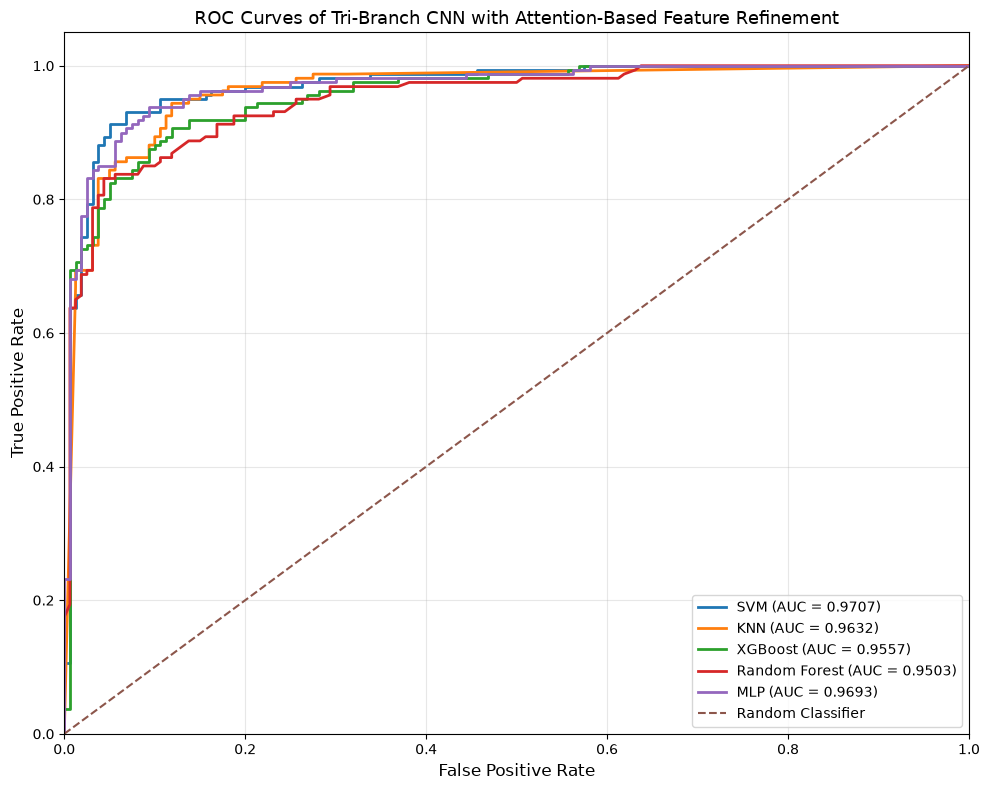

In [101]:
# ============================================================
# STEP 40: ROC-AUC CURVES FOR ALL CLASSIFIERS
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


# ------------------------------------------------------------
# Calculate ROC curves
# ------------------------------------------------------------

fpr_svm, tpr_svm, _ = roc_curve(
    y_test,
    svm_prob
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    knn_prob
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    xgb_prob
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_prob
)

fpr_mlp, tpr_mlp, _ = roc_curve(
    y_test,
    mlp_prob
)


# ------------------------------------------------------------
# Calculate AUC
# ------------------------------------------------------------

auc_svm = roc_auc_score(
    y_test,
    svm_prob
)

auc_knn = roc_auc_score(
    y_test,
    knn_prob
)

auc_xgb = roc_auc_score(
    y_test,
    xgb_prob
)

auc_rf = roc_auc_score(
    y_test,
    rf_prob
)

auc_mlp = roc_auc_score(
    y_test,
    mlp_prob
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 8)
)


plt.plot(
    fpr_svm,
    tpr_svm,
    linewidth=2,
    label=f"SVM (AUC = {auc_svm:.4f})"
)


plt.plot(
    fpr_knn,
    tpr_knn,
    linewidth=2,
    label=f"KNN (AUC = {auc_knn:.4f})"
)


plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f"XGBoost (AUC = {auc_xgb:.4f})"
)


plt.plot(
    fpr_rf,
    tpr_rf,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)


plt.plot(
    fpr_mlp,
    tpr_mlp,
    linewidth=2,
    label=f"MLP (AUC = {auc_mlp:.4f})"
)


# ------------------------------------------------------------
# Random classifier reference
# ------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


# ------------------------------------------------------------
# Labels and title
# ------------------------------------------------------------

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves of Tri-Branch CNN with Attention-Based Feature Refinement",
    fontsize=13
)


plt.legend(
    loc="lower right",
    fontsize=10
)


plt.grid(
    alpha=0.3
)


plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1.05
)


plt.tight_layout()


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "TriBranch_Attention_ROC_All_Classifiers.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()

In [103]:
# ============================================================
# STEP 42: INSTALL OPTUNA
# ============================================================

!pip install -q optuna

In [104]:
# ============================================================
# STEP 42.1: IMPORT OPTUNA
# ============================================================

import optuna
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier


print("Optuna imported successfully.")

Optuna imported successfully.


In [105]:
# ============================================================
# STEP 43: STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

cv_strategy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

print("Using Stratified 10-Fold Cross-Validation")

Using Stratified 10-Fold Cross-Validation


In [106]:
# ============================================================
# STEP 44: OPTUNA - SVM
# ============================================================

def objective_svm(trial):

    C = trial.suggest_float(
        "C",
        1e-2,
        1e2,
        log=True
    )

    gamma = trial.suggest_float(
        "gamma",
        1e-5,
        1e0,
        log=True
    )


    model = SVC(
        kernel="rbf",
        C=C,
        gamma=gamma,
        random_state=42
    )


    cv_scores = []


    for train_idx, val_idx in cv_strategy.split(
        X_train_attention,
        y_train
    ):

        X_tr = X_train_attention[train_idx]
        X_cv = X_train_attention[val_idx]

        y_tr = y_train[train_idx]
        y_cv = y_train[val_idx]


        model.fit(
            X_tr,
            y_tr
        )


        predictions = model.predict(
            X_cv
        )


        score = accuracy_score(
            y_cv,
            predictions
        )


        cv_scores.append(score)


    return np.mean(cv_scores)

In [107]:
# ============================================================
# STEP 45: RUN OPTUNA FOR SVM
# ============================================================

svm_study = optuna.create_study(
    direction="maximize",
    study_name="SVM_Optimization"
)


svm_study.optimize(
    objective_svm,
    n_trials=50
)


print("=" * 70)
print("BEST SVM PARAMETERS")
print("=" * 70)

print(
    svm_study.best_params
)

print(
    f"Best CV Accuracy: "
    f"{svm_study.best_value * 100:.2f}%"
)

print("=" * 70)

[I 2026-09-10 09:37:47,121] A new study created in memory with name: SVM_Optimization
[I 2026-09-10 09:37:50,395] Trial 0 finished with value: 0.821484375 and parameters: {'C': 0.22980650552002502, 'gamma': 0.0001994301035216711}. Best is trial 0 with value: 0.821484375.
[I 2026-09-10 09:37:52,788] Trial 1 finished with value: 0.860546875 and parameters: {'C': 12.055686579113152, 'gamma': 1.5662004287647674e-05}. Best is trial 1 with value: 0.860546875.
[I 2026-09-10 09:37:55,061] Trial 2 finished with value: 0.877734375 and parameters: {'C': 0.09629497779271945, 'gamma': 0.0064535628249930066}. Best is trial 2 with value: 0.877734375.
[I 2026-09-10 09:37:56,671] Trial 3 finished with value: 0.949609375 and parameters: {'C': 3.775543974197542, 'gamma': 0.0004397987306117136}. Best is trial 3 with value: 0.949609375.
[I 2026-09-10 09:38:00,360] Trial 4 finished with value: 0.809375 and parameters: {'C': 0.06458119756559581, 'gamma': 0.0004412100515365924}. Best is trial 3 with value: 0.

BEST SVM PARAMETERS
{'C': 83.181206466776, 'gamma': 0.00031004023882119647}
Best CV Accuracy: 98.55%


In [108]:
# ============================================================
# STEP 46: CREATE OPTIMIZED SVM
# ============================================================

best_svm = SVC(
    kernel="rbf",

    C=svm_study.best_params["C"],

    gamma=svm_study.best_params["gamma"],

    probability=True,

    random_state=42
)

best_svm.fit(
    X_train_attention,
    y_train
)

print("Optimized SVM trained successfully.")

C:\Users\student\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Optimized SVM trained successfully.


In [109]:

# ============================================================
# STEP 47: OPTUNA - KNN
# ============================================================

def objective_knn(trial):

    n_neighbors = trial.suggest_int(
        "n_neighbors",
        3,
        21,
        step=2
    )


    weights = trial.suggest_categorical(
        "weights",
        [
            "uniform",
            "distance"
        ]
    )


    metric = trial.suggest_categorical(
        "metric",
        [
            "euclidean",
            "manhattan",
            "minkowski"
        ]
    )


    model = KNeighborsClassifier(

        n_neighbors=n_neighbors,

        weights=weights,

        metric=metric
    )


    cv_scores = []


    for train_idx, val_idx in cv_strategy.split(
        X_train_attention,
        y_train
    ):

        X_tr = X_train_attention[train_idx]
        X_cv = X_train_attention[val_idx]

        y_tr = y_train[train_idx]
        y_cv = y_train[val_idx]


        model.fit(
            X_tr,
            y_tr
        )


        predictions = model.predict(
            X_cv
        )


        score = accuracy_score(
            y_cv,
            predictions
        )


        cv_scores.append(score)


    return np.mean(cv_scores)

In [110]:
# ============================================================
# STEP 48: RUN OPTUNA FOR KNN
# ============================================================

knn_study = optuna.create_study(
    direction="maximize",
    study_name="KNN_Optimization"
)


knn_study.optimize(
    objective_knn,
    n_trials=50
)


print("=" * 70)
print("BEST KNN PARAMETERS")
print("=" * 70)

print(
    knn_study.best_params
)

print(
    f"Best CV Accuracy: "
    f"{knn_study.best_value * 100:.2f}%"
)

print("=" * 70)

[I 2026-09-10 09:39:05,968] A new study created in memory with name: KNN_Optimization
[I 2026-09-10 09:39:06,137] Trial 0 finished with value: 0.90859375 and parameters: {'n_neighbors': 11, 'weights': 'distance', 'metric': 'minkowski'}. Best is trial 0 with value: 0.90859375.
[I 2026-09-10 09:39:06,300] Trial 1 finished with value: 0.91328125 and parameters: {'n_neighbors': 9, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 1 with value: 0.91328125.
[I 2026-09-10 09:39:06,454] Trial 2 finished with value: 0.91640625 and parameters: {'n_neighbors': 5, 'weights': 'uniform', 'metric': 'minkowski'}. Best is trial 2 with value: 0.91640625.
[I 2026-09-10 09:39:06,610] Trial 3 finished with value: 0.9203125 and parameters: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'euclidean'}. Best is trial 3 with value: 0.9203125.
[I 2026-09-10 09:39:06,749] Trial 4 finished with value: 0.9203125 and parameters: {'n_neighbors': 3, 'weights': 'uniform', 'metric': 'minkowski'}. Best is 

BEST KNN PARAMETERS
{'n_neighbors': 3, 'weights': 'distance', 'metric': 'euclidean'}
Best CV Accuracy: 92.03%


In [111]:
# ============================================================
# STEP 49: CREATE OPTIMIZED KNN
# ============================================================

best_knn = KNeighborsClassifier(

    n_neighbors=
        knn_study.best_params[
            "n_neighbors"
        ],

    weights=
        knn_study.best_params[
            "weights"
        ],

    metric=
        knn_study.best_params[
            "metric"
        ]
)


best_knn.fit(
    X_train_attention,
    y_train
)


print("Optimized KNN trained.")

Optimized KNN trained.


In [112]:
# ============================================================
# STEP 50: OPTUNA - RANDOM FOREST
# ============================================================

def objective_rf(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        500,
        step=50
    )


    max_depth = trial.suggest_int(
        "max_depth",
        5,
        40
    )


    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2,
        10
    )


    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf",
        1,
        5
    )


    max_features = trial.suggest_categorical(
        "max_features",
        [
            "sqrt",
            "log2"
        ]
    )


    model = RandomForestClassifier(

        n_estimators=n_estimators,

        max_depth=max_depth,

        min_samples_split=min_samples_split,

        min_samples_leaf=min_samples_leaf,

        max_features=max_features,

        class_weight="balanced",

        random_state=42,

        n_jobs=-1
    )


    cv_scores = []


    for train_idx, val_idx in cv_strategy.split(
        X_train_attention,
        y_train
    ):

        X_tr = X_train_attention[train_idx]
        X_cv = X_train_attention[val_idx]

        y_tr = y_train[train_idx]
        y_cv = y_train[val_idx]


        model.fit(
            X_tr,
            y_tr
        )


        predictions = model.predict(
            X_cv
        )


        score = accuracy_score(
            y_cv,
            predictions
        )


        cv_scores.append(score)


    return np.mean(cv_scores)

In [113]:
# ============================================================
# STEP 51: RUN OPTUNA FOR RANDOM FOREST
# ============================================================

rf_study = optuna.create_study(
    direction="maximize",
    study_name="RandomForest_Optimization"
)


rf_study.optimize(
    objective_rf,
    n_trials=50
)


print("=" * 70)
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 70)

print(
    rf_study.best_params
)

print(
    f"Best CV Accuracy: "
    f"{rf_study.best_value * 100:.2f}%"
)

print("=" * 70)

[I 2026-09-10 09:39:18,234] A new study created in memory with name: RandomForest_Optimization
[I 2026-09-10 09:39:21,478] Trial 0 finished with value: 0.90234375 and parameters: {'n_estimators': 150, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 0 with value: 0.90234375.
[I 2026-09-10 09:39:25,375] Trial 1 finished with value: 0.900390625 and parameters: {'n_estimators': 200, 'max_depth': 37, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 'log2'}. Best is trial 0 with value: 0.90234375.
[I 2026-09-10 09:39:34,872] Trial 2 finished with value: 0.90703125 and parameters: {'n_estimators': 350, 'max_depth': 37, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.90703125.
[I 2026-09-10 09:39:43,609] Trial 3 finished with value: 0.9 and parameters: {'n_estimators': 350, 'max_depth': 40, 'min_samples_split': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is tri

BEST RANDOM FOREST PARAMETERS
{'n_estimators': 400, 'max_depth': 27, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Best CV Accuracy: 91.21%


In [114]:
# ============================================================
# STEP 52: CREATE OPTIMIZED RANDOM FOREST
# ============================================================

best_rf = RandomForestClassifier(

    n_estimators=
        rf_study.best_params[
            "n_estimators"
        ],

    max_depth=
        rf_study.best_params[
            "max_depth"
        ],

    min_samples_split=
        rf_study.best_params[
            "min_samples_split"
        ],

    min_samples_leaf=
        rf_study.best_params[
            "min_samples_leaf"
        ],

    max_features=
        rf_study.best_params[
            "max_features"
        ],

    class_weight="balanced",

    random_state=42,

    n_jobs=-1
)


best_rf.fit(
    X_train_attention,
    y_train
)


print("Optimized Random Forest trained.")

Optimized Random Forest trained.


In [115]:
# ============================================================
# STEP 53: OPTUNA - XGBOOST
# ============================================================

def objective_xgb(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        500,
        step=50
    )


    max_depth = trial.suggest_int(
        "max_depth",
        3,
        10
    )


    learning_rate = trial.suggest_float(
        "learning_rate",
        0.01,
        0.2,
        log=True
    )


    subsample = trial.suggest_float(
        "subsample",
        0.6,
        1.0
    )


    colsample_bytree = trial.suggest_float(
        "colsample_bytree",
        0.6,
        1.0
    )


    min_child_weight = trial.suggest_int(
        "min_child_weight",
        1,
        10
    )


    model = XGBClassifier(

        n_estimators=n_estimators,

        max_depth=max_depth,

        learning_rate=learning_rate,

        subsample=subsample,

        colsample_bytree=colsample_bytree,

        min_child_weight=min_child_weight,

        objective="binary:logistic",

        eval_metric="logloss",

        random_state=42,

        n_jobs=-1
    )


    cv_scores = []


    for train_idx, val_idx in cv_strategy.split(
        X_train_attention,
        y_train
    ):

        X_tr = X_train_attention[train_idx]
        X_cv = X_train_attention[val_idx]

        y_tr = y_train[train_idx]
        y_cv = y_train[val_idx]


        model.fit(
            X_tr,
            y_tr
        )


        predictions = model.predict(
            X_cv
        )


        score = accuracy_score(
            y_cv,
            predictions
        )


        cv_scores.append(score)


    return np.mean(cv_scores)

In [116]:
# ============================================================
# STEP 54: RUN OPTUNA FOR XGBOOST
# ============================================================

xgb_study = optuna.create_study(
    direction="maximize",
    study_name="XGBoost_Optimization"
)


xgb_study.optimize(
    objective_xgb,
    n_trials=50
)


print("=" * 70)
print("BEST XGBOOST PARAMETERS")
print("=" * 70)

print(
    xgb_study.best_params
)

print(
    f"Best CV Accuracy: "
    f"{xgb_study.best_value * 100:.2f}%"
)

print("=" * 70)

[I 2026-09-10 09:46:58,673] A new study created in memory with name: XGBoost_Optimization
[I 2026-09-10 09:47:09,246] Trial 0 finished with value: 0.91328125 and parameters: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.04269783751697888, 'subsample': 0.7454417221615207, 'colsample_bytree': 0.6677903485360603, 'min_child_weight': 2}. Best is trial 0 with value: 0.91328125.
[I 2026-09-10 09:47:47,688] Trial 1 finished with value: 0.942578125 and parameters: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.0351380489364435, 'subsample': 0.7213259851558128, 'colsample_bytree': 0.7960256854983789, 'min_child_weight': 3}. Best is trial 1 with value: 0.942578125.
[I 2026-09-10 09:48:11,919] Trial 2 finished with value: 0.937890625 and parameters: {'n_estimators': 300, 'max_depth': 9, 'learning_rate': 0.06270787314034057, 'subsample': 0.7450390255937297, 'colsample_bytree': 0.6603546355416976, 'min_child_weight': 8}. Best is trial 1 with value: 0.942578125.
[I 2026-09-10 09

BEST XGBOOST PARAMETERS
{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.12069671548729757, 'subsample': 0.7115921580047363, 'colsample_bytree': 0.7743624116392166, 'min_child_weight': 5}
Best CV Accuracy: 94.96%


In [117]:
# ============================================================
# STEP 55: CREATE OPTIMIZED XGBOOST
# ============================================================

best_xgb = XGBClassifier(

    **xgb_study.best_params,

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42,

    n_jobs=-1
)


best_xgb.fit(
    X_train_attention,
    y_train
)


print("Optimized XGBoost trained.")

Optimized XGBoost trained.


In [118]:
# ============================================================
# STEP 56: OPTUNA - MLP
# ============================================================

def objective_mlp(trial):

    hidden_type = trial.suggest_categorical(
        "hidden_type",
        [
            "128",
            "256",
            "128_64",
            "256_128",
            "256_128_64"
        ]
    )


    if hidden_type == "128":

        hidden_layer_sizes = (128,)

    elif hidden_type == "256":

        hidden_layer_sizes = (256,)

    elif hidden_type == "128_64":

        hidden_layer_sizes = (128, 64)

    elif hidden_type == "256_128":

        hidden_layer_sizes = (256, 128)

    else:

        hidden_layer_sizes = (
            256,
            128,
            64
        )


    activation = trial.suggest_categorical(
        "activation",
        [
            "relu",
            "tanh"
        ]
    )


    alpha = trial.suggest_float(
        "alpha",
        1e-6,
        1e-2,
        log=True
    )


    learning_rate_init = trial.suggest_float(
        "learning_rate_init",
        1e-4,
        1e-2,
        log=True
    )


    model = MLPClassifier(

        hidden_layer_sizes=
            hidden_layer_sizes,

        activation=activation,

        solver="adam",

        alpha=alpha,

        learning_rate_init=
            learning_rate_init,

        max_iter=300,

        early_stopping=True,

        validation_fraction=0.15,

        n_iter_no_change=15,

        random_state=42
    )


    cv_scores = []


    for train_idx, val_idx in cv_strategy.split(
        X_train_attention,
        y_train
    ):

        X_tr = X_train_attention[train_idx]
        X_cv = X_train_attention[val_idx]

        y_tr = y_train[train_idx]
        y_cv = y_train[val_idx]


        model.fit(
            X_tr,
            y_tr
        )


        predictions = model.predict(
            X_cv
        )


        score = accuracy_score(
            y_cv,
            predictions
        )


        cv_scores.append(score)


    return np.mean(cv_scores)

In [119]:
# ============================================================
# STEP 57: RUN OPTUNA FOR MLP
# ============================================================

mlp_study = optuna.create_study(
    direction="maximize",
    study_name="MLP_Optimization"
)


mlp_study.optimize(
    objective_mlp,
    n_trials=50
)


print("=" * 70)
print("BEST MLP PARAMETERS")
print("=" * 70)

print(
    mlp_study.best_params
)

print(
    f"Best CV Accuracy: "
    f"{mlp_study.best_value * 100:.2f}%"
)

print("=" * 70)

[I 2026-09-10 10:05:11,547] A new study created in memory with name: MLP_Optimization
[I 2026-09-10 10:05:28,423] Trial 0 finished with value: 0.97421875 and parameters: {'hidden_type': '256_128_64', 'activation': 'relu', 'alpha': 8.637063582814815e-06, 'learning_rate_init': 0.00010269742522966417}. Best is trial 0 with value: 0.97421875.
[I 2026-09-10 10:05:32,825] Trial 1 finished with value: 0.98046875 and parameters: {'hidden_type': '128_64', 'activation': 'relu', 'alpha': 0.00045748028489076654, 'learning_rate_init': 0.004606223275683781}. Best is trial 1 with value: 0.98046875.
[I 2026-09-10 10:05:40,575] Trial 2 finished with value: 0.983203125 and parameters: {'hidden_type': '256', 'activation': 'relu', 'alpha': 5.2432575454628294e-05, 'learning_rate_init': 0.0010153676032378198}. Best is trial 2 with value: 0.983203125.
[I 2026-09-10 10:05:49,759] Trial 3 finished with value: 0.98046875 and parameters: {'hidden_type': '256_128', 'activation': 'tanh', 'alpha': 2.729484390716917

BEST MLP PARAMETERS
{'hidden_type': '128', 'activation': 'tanh', 'alpha': 6.1507548254162315e-06, 'learning_rate_init': 0.0018032671110951531}
Best CV Accuracy: 98.44%


In [120]:
# ============================================================
# STEP 58: CREATE OPTIMIZED MLP
# ============================================================

hidden_type = mlp_study.best_params[
    "hidden_type"
]


if hidden_type == "128":

    best_hidden_layers = (128,)

elif hidden_type == "256":

    best_hidden_layers = (256,)

elif hidden_type == "128_64":

    best_hidden_layers = (128, 64)

elif hidden_type == "256_128":

    best_hidden_layers = (256, 128)

else:

    best_hidden_layers = (
        256,
        128,
        64
    )


best_mlp = MLPClassifier(

    hidden_layer_sizes=
        best_hidden_layers,

    activation=
        mlp_study.best_params[
            "activation"
        ],

    solver="adam",

    alpha=
        mlp_study.best_params[
            "alpha"
        ],

    learning_rate_init=
        mlp_study.best_params[
            "learning_rate_init"
        ],

    max_iter=300,

    early_stopping=True,

    validation_fraction=0.15,

    n_iter_no_change=15,

    random_state=42
)


best_mlp.fit(
    X_train_attention,
    y_train
)


print("Optimized MLP trained.")

Optimized MLP trained.


In [121]:
# ============================================================
# STEP 59: OPTUNA OPTIMIZATION SUMMARY
# ============================================================

optuna_results = pd.DataFrame({

    "Classifier": [

        "SVM",

        "KNN",

        "XGBoost",

        "MLP",

        "Random Forest"
    ],

    "Best CV Accuracy (%)": [

        svm_study.best_value * 100,

        knn_study.best_value * 100,

        xgb_study.best_value * 100,

        mlp_study.best_value * 100,

        rf_study.best_value * 100
    ]
})


optuna_results = (
    optuna_results
    .sort_values(
        "Best CV Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)


optuna_results[
    "Best CV Accuracy (%)"
] = (
    optuna_results[
        "Best CV Accuracy (%)"
    ].round(2)
)


print("=" * 70)

print(
    "OPTUNA HYPERPARAMETER OPTIMIZATION"
)

print("=" * 70)

print(
    optuna_results.to_string(
        index=False
    )
)

print("=" * 70)

OPTUNA HYPERPARAMETER OPTIMIZATION
   Classifier  Best CV Accuracy (%)
          SVM                 98.55
          MLP                 98.44
      XGBoost                 94.96
          KNN                 92.03
Random Forest                 91.21


In [122]:
# ============================================================
# STEP 60: SAVE OPTUNA PARAMETERS
# ============================================================

optuna_parameter_df = pd.DataFrame({

    "Classifier": [
        "SVM",
        "KNN",
        "XGBoost",
        "MLP",
        "Random Forest"
    ],

    "Best Parameters": [

        str(
            svm_study.best_params
        ),

        str(
            knn_study.best_params
        ),

        str(
            xgb_study.best_params
        ),

        str(
            mlp_study.best_params
        ),

        str(
            rf_study.best_params
        )
    ],

    "Best CV Accuracy (%)": [

        svm_study.best_value * 100,

        knn_study.best_value * 100,

        xgb_study.best_value * 100,

        mlp_study.best_value * 100,

        rf_study.best_value * 100
    ]
})


optuna_parameter_df.to_excel(
    "TriBranch_Attention_Optuna_Parameters.xlsx",
    index=False
)


print(
    "Optuna results saved successfully."
)

Optuna results saved successfully.


In [123]:
# ============================================================
# STEP 61: FINAL OPTIMIZED CLASSIFIERS
# ============================================================

optimized_classifiers = {

    "SVM":
        best_svm,

    "KNN":
        best_knn,

    "XGBoost":
        best_xgb,

    "MLP":
        best_mlp,

    "Random Forest":
        best_rf
}


print("=" * 70)

print(
    "OPTIMIZED CLASSIFIERS READY"
)

print("=" * 70)

for name in optimized_classifiers:

    print(
        name,
        "✓"
    )

print("=" * 70)

OPTIMIZED CLASSIFIERS READY
SVM ✓
KNN ✓
XGBoost ✓
MLP ✓
Random Forest ✓


In [124]:
# ============================================================
# STEP 62: PREDICTIONS FROM OPTIMIZED CLASSIFIERS
# ============================================================

optimized_predictions = {}
optimized_probabilities = {}

for name, model in optimized_classifiers.items():

    # Prediction
    y_pred = model.predict(
        X_test_attention
    )

    # Probability for positive class
    y_prob = model.predict_proba(
        X_test_attention
    )[:, 1]

    optimized_predictions[name] = y_pred
    optimized_probabilities[name] = y_prob

    print(
        f"{name}: predictions generated successfully."
    )

SVM: predictions generated successfully.
KNN: predictions generated successfully.
XGBoost: predictions generated successfully.
MLP: predictions generated successfully.
Random Forest: predictions generated successfully.


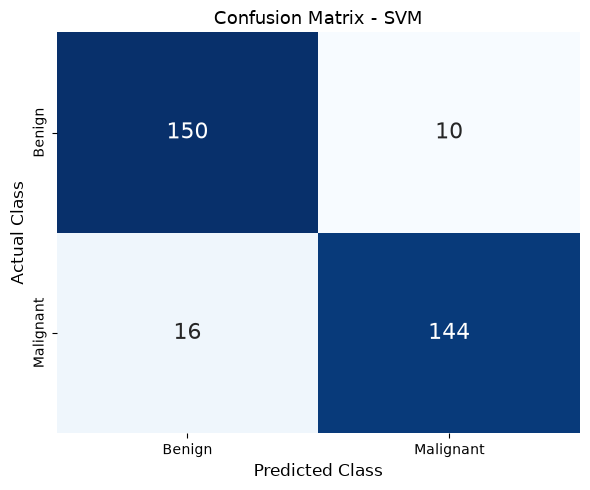

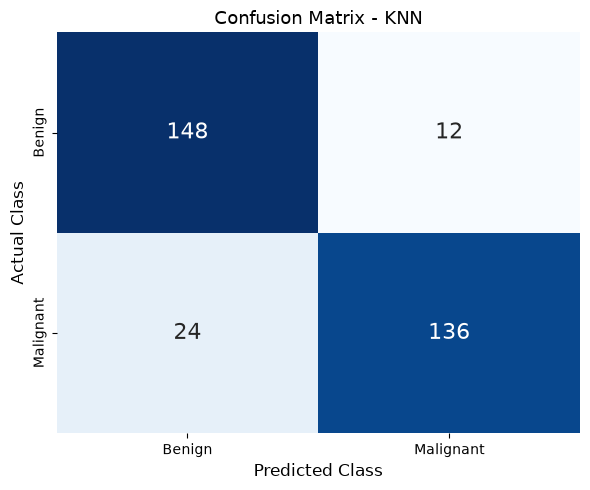

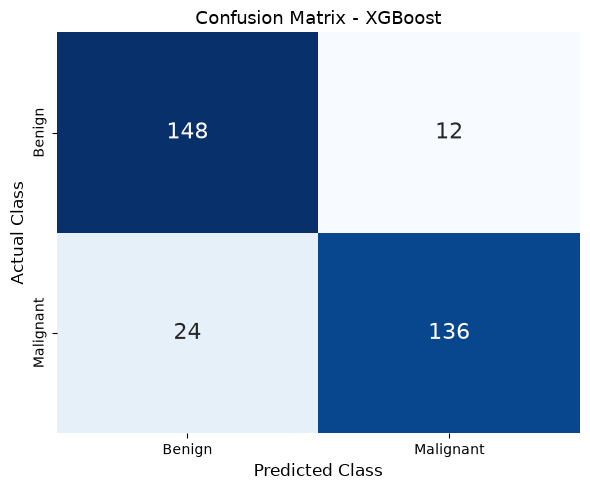

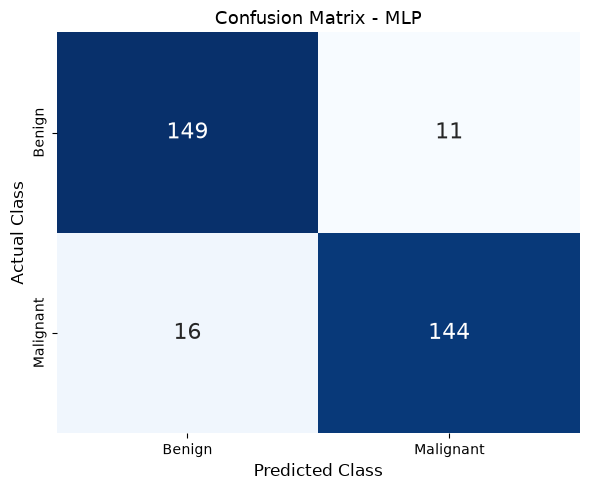

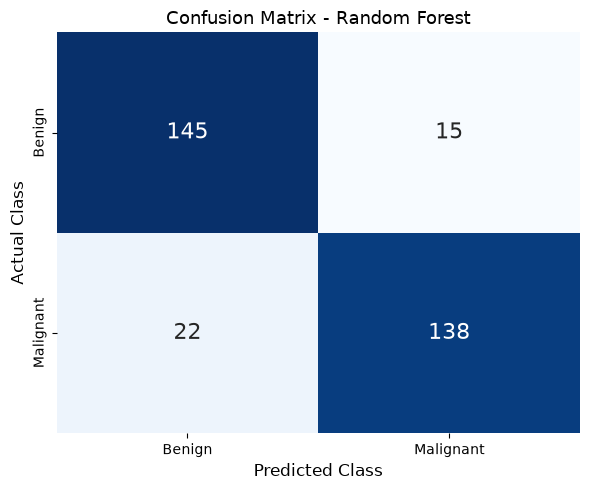

In [125]:
# ============================================================
# STEP 63: CONFUSION MATRIX FOR EACH OPTIMIZED CLASSIFIER
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix


for name in optimized_classifiers:

    y_pred = optimized_predictions[name]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=[
            "Benign",
            "Malignant"
        ],
        yticklabels=[
            "Benign",
            "Malignant"
        ],
        annot_kws={
            "size": 16
        }
    )

    plt.xlabel(
        "Predicted Class",
        fontsize=12
    )

    plt.ylabel(
        "Actual Class",
        fontsize=12
    )

    plt.title(
        f"Confusion Matrix - {name}",
        fontsize=13
    )

    plt.tight_layout()

    filename = (
        "Confusion_Matrix_"
        + name.replace(" ", "_")
        + ".png"
    )

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [126]:
# ============================================================
# STEP 64: ALL PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score
)

import numpy as np


final_results = []


for name in optimized_classifiers:

    y_pred = optimized_predictions[name]

    y_prob = optimized_probabilities[name]


    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )


    # --------------------------------------------------------
    # Precision
    # --------------------------------------------------------

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # Sensitivity / Recall
    # --------------------------------------------------------

    sensitivity = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # Specificity
    # --------------------------------------------------------

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # --------------------------------------------------------
    # F1 Score
    # --------------------------------------------------------

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # Jaccard Index
    # --------------------------------------------------------

    jaccard = jaccard_score(
        y_test,
        y_pred,
        zero_division=0
    )


    # --------------------------------------------------------
    # G-Mean
    # --------------------------------------------------------

    gmean = np.sqrt(
        sensitivity * specificity
    )


    # --------------------------------------------------------
    # Error Rate
    # --------------------------------------------------------

    error_rate = (
        1 - accuracy
    )


    # --------------------------------------------------------
    # MCC
    # --------------------------------------------------------

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )


    # --------------------------------------------------------
    # Cohen's Kappa
    # --------------------------------------------------------

    kappa = cohen_kappa_score(
        y_test,
        y_pred
    )


    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )


    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    final_results.append({

        "Classifier": name,

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Sensitivity (%)":
            sensitivity * 100,

        "Specificity (%)":
            specificity * 100,

        "F1 Score (%)":
            f1 * 100,

        "Jaccard (%)":
            jaccard * 100,

        "G-Mean (%)":
            gmean * 100,

        "Error Rate (%)":
            error_rate * 100,

        "MCC":
            mcc,

        "Kappa":
            kappa,

        "ROC-AUC":
            roc_auc,

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })


final_performance_df = pd.DataFrame(
    final_results
)


print(
    final_performance_df.round(4).to_string(
        index=False
    )
)

   Classifier  Accuracy (%)  Precision (%)  Sensitivity (%)  Specificity (%)  F1 Score (%)  Jaccard (%)  G-Mean (%)  Error Rate (%)    MCC  Kappa  ROC-AUC  TN  FP  FN  TP
          SVM       91.8750        93.5065            90.00           93.750       91.7197      84.7059     91.8559          8.1250 0.8381 0.8375   0.9670 150  10  16 144
          KNN       88.7500        91.8919            85.00           92.500       88.3117      79.0698     88.6707         11.2500 0.7772 0.7750   0.9455 148  12  24 136
      XGBoost       88.7500        91.8919            85.00           92.500       88.3117      79.0698     88.6707         11.2500 0.7772 0.7750   0.9611 148  12  24 136
          MLP       91.5625        92.9032            90.00           93.125       91.4286      84.2105     91.5492          8.4375 0.8317 0.8312   0.9685 149  11  16 144
Random Forest       88.4375        90.1961            86.25           90.625       88.1789      78.8571     88.4104         11.5625 0.7695 0.7688

In [127]:
# ============================================================
# STEP 65: DISPLAY METRICS ONE BY ONE
# ============================================================

for _, row in final_performance_df.iterrows():

    print("\n")
    print("=" * 65)

    print(
        f"CLASSIFIER: {row['Classifier']}"
    )

    print("=" * 65)

    print(
        f"Accuracy       : {row['Accuracy (%)']:.2f}%"
    )

    print(
        f"Precision      : {row['Precision (%)']:.2f}%"
    )

    print(
        f"Sensitivity    : {row['Sensitivity (%)']:.2f}%"
    )

    print(
        f"Specificity    : {row['Specificity (%)']:.2f}%"
    )

    print(
        f"F1 Score       : {row['F1 Score (%)']:.2f}%"
    )

    print(
        f"Jaccard Index  : {row['Jaccard (%)']:.2f}%"
    )

    print(
        f"G-Mean         : {row['G-Mean (%)']:.2f}%"
    )

    print(
        f"Error Rate     : {row['Error Rate (%)']:.2f}%"
    )

    print(
        f"MCC            : {row['MCC']:.4f}"
    )

    print(
        f"Kappa          : {row['Kappa']:.4f}"
    )

    print(
        f"ROC-AUC        : {row['ROC-AUC']:.4f}"
    )

    print("-" * 65)

    print(
        f"True Negative  : {row['TN']}"
    )

    print(
        f"False Positive : {row['FP']}"
    )

    print(
        f"False Negative : {row['FN']}"
    )

    print(
        f"True Positive  : {row['TP']}"
    )

    print("=" * 65)



CLASSIFIER: SVM
Accuracy       : 91.88%
Precision      : 93.51%
Sensitivity    : 90.00%
Specificity    : 93.75%
F1 Score       : 91.72%
Jaccard Index  : 84.71%
G-Mean         : 91.86%
Error Rate     : 8.13%
MCC            : 0.8381
Kappa          : 0.8375
ROC-AUC        : 0.9670
-----------------------------------------------------------------
True Negative  : 150
False Positive : 10
False Negative : 16
True Positive  : 144


CLASSIFIER: KNN
Accuracy       : 88.75%
Precision      : 91.89%
Sensitivity    : 85.00%
Specificity    : 92.50%
F1 Score       : 88.31%
Jaccard Index  : 79.07%
G-Mean         : 88.67%
Error Rate     : 11.25%
MCC            : 0.7772
Kappa          : 0.7750
ROC-AUC        : 0.9455
-----------------------------------------------------------------
True Negative  : 148
False Positive : 12
False Negative : 24
True Positive  : 136


CLASSIFIER: XGBoost
Accuracy       : 88.75%
Precision      : 91.89%
Sensitivity    : 85.00%
Specificity    : 92.50%
F1 Score       : 88.31%

In [128]:
# ============================================================
# STEP 66: FINAL PERFORMANCE COMPARISON
# ============================================================

display_columns = [

    "Classifier",

    "Accuracy (%)",

    "Precision (%)",

    "Sensitivity (%)",

    "Specificity (%)",

    "F1 Score (%)",

    "Jaccard (%)",

    "G-Mean (%)",

    "Error Rate (%)",

    "MCC",

    "Kappa",

    "ROC-AUC"
]


publication_table = (
    final_performance_df[
        display_columns
    ]
    .copy()
)


for column in display_columns[1:9]:

    publication_table[column] = (
        publication_table[column]
        .round(2)
    )


publication_table["MCC"] = (
    publication_table["MCC"]
    .round(4)
)


publication_table["Kappa"] = (
    publication_table["Kappa"]
    .round(4)
)


publication_table["ROC-AUC"] = (
    publication_table["ROC-AUC"]
    .round(4)
)


print(
    publication_table.to_string(
        index=False
    )
)

   Classifier  Accuracy (%)  Precision (%)  Sensitivity (%)  Specificity (%)  F1 Score (%)  Jaccard (%)  G-Mean (%)  Error Rate (%)    MCC  Kappa  ROC-AUC
          SVM         91.88          93.51            90.00            93.75         91.72        84.71       91.86            8.13 0.8381 0.8375   0.9670
          KNN         88.75          91.89            85.00            92.50         88.31        79.07       88.67           11.25 0.7772 0.7750   0.9455
      XGBoost         88.75          91.89            85.00            92.50         88.31        79.07       88.67           11.25 0.7772 0.7750   0.9611
          MLP         91.56          92.90            90.00            93.12         91.43        84.21       91.55            8.44 0.8317 0.8312   0.9685
Random Forest         88.44          90.20            86.25            90.62         88.18        78.86       88.41           11.56 0.7695 0.7688   0.9506


In [129]:
# ============================================================
# STEP 67: SAVE FINAL PERFORMANCE RESULTS
# ============================================================

with pd.ExcelWriter(
    "TriBranch_Attention_Optuna_Final_Results.xlsx"
) as writer:

    publication_table.to_excel(
        writer,
        sheet_name="Performance Metrics",
        index=False
    )

    final_performance_df[
        [
            "Classifier",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ].to_excel(
        writer,
        sheet_name="Confusion Matrix Values",
        index=False
    )


print(
    "Final results saved successfully."
)

Final results saved successfully.
